# Examining Sub-Research Question 2

The second sub-research question is as follows: **'To what extent does the media type of the source material influence the content of the fan fictions on Archive of Our Own??'**

In [4]:
# Import package
import polars as pl
import numpy as np
import matplotlib.pyplot as plt

In [5]:
df_metadata = pl.read_ndjson("./data/combined_metadata.jsonl") # Create the df_metadata DataFrame
df_metadata = df_metadata.unnest('metadata') # Turn the metadata column into 18 separate columns

fandoms = ["DC's Legends of Tomorrow (TV)", "Avatar: The Last Airbender (Cartoon 2005)", "Spider-Man: Spider-Verse (Sony Animated Movies)"]

# Select the target fandom and relationship categories
df_metadata = df_metadata.filter(
    ((pl.col("Fandom") == fandoms[0]) |
    (pl.col("Fandom") == fandoms[1]) |
    (pl.col("Fandom") == fandoms[2])) &
    ((pl.col("Category") == "F/F") |
    (pl.col("Category") == "M/M") |
    (pl.col("Category") == "F/M"))
)

df_metadata.head()

id,title,Additional Tags,Archive Warning,Category,Characters,Fandoms,Language,Rating,Relationship,author,chapters,completed,published,words,Fandom,Character,Collections,Series,Relationships
str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""10012010""","""Just One Training""","""Explicit Sexual Content, Oral …","""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart, Mic…",null,"""English""","""Explicit""","""Sara Lance/Leonard Snart""","""by capnwho""","""1/1""","""""","""2017-02-28""","""1,470""","""DC's Legends of Tomorrow (TV)""",null,null,"""Just One Fixation""",null
"""10013705""","""Five Months More""","""Established Relationship, surp…","""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart""",null,"""English""","""Not Rated""",null,"""by flabbergabst""","""1/1""","""""","""2017-02-28""","""505""","""DC's Legends of Tomorrow (TV)""",null,null,"""The Captain Canary Collection""","""Sara Lance/Leonard Snart, Capt…"
"""10018964""","""It Ends with a Kiss""","""Alpha/Beta/Omega Dynamics, Min…","""No Archive Warnings Apply""","""M/M""","""Leonard Snart, Ray Palmer, Mic…",null,"""English""","""Teen And Up Audiences""","""Ray Palmer/Leonard Snart""","""by Constantsnow""","""1/1""","""""","""2017-02-28""","""3,008""","""DC's Legends of Tomorrow (TV)""",null,null,null,null
"""10030784""","""Bet""",null,"""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart, Mic…",null,"""English""","""General Audiences""","""Sara Lance/Leonard Snart""","""by orphan_account""","""1/1""","""""","""2017-03-01""","""1,273""","""DC's Legends of Tomorrow (TV)""",null,null,null,null
"""10033958""","""For the Both of Us""","""Captain Canary, ficcingcaptain…","""No Archive Warnings Apply""","""F/M""","""Sara Lance, Leonard Snart, Mic…",null,"""English""","""Not Rated""",null,"""by flabbergabst""","""1/1""","""""","""2017-03-01""","""1,067""","""DC's Legends of Tomorrow (TV)""",null,null,"""The Captain Canary Collection""","""Sara Lance/Leonard Snart, Capt…"


In [6]:
# Count the amount of fan works per fandom and category composition
# Filtered by F/F + M/M
ff_mm_tv_amt = df_metadata.filter(
    ((pl.col("Category") == "F/F") |
    (pl.col("Category") == "M/M")) &
    ((pl.col("Fandom") == fandoms[0]) |
    (pl.col("Fandom") == fandoms[1]))
).select(pl.len())
ff_mm_film_amt = df_metadata.filter(
    ((pl.col("Category") == "F/F") |
    (pl.col("Category") == "M/M")) &
    (pl.col("Fandom") == fandoms[2])
).select(pl.len())

# Filtered by F/M
fm_tv_amt = df_metadata.filter(
    (pl.col("Category") == "F/M") &
    ((pl.col("Fandom") == fandoms[0]) |
    (pl.col("Fandom") == fandoms[1]))
).select(pl.len())
fm_film_amt = df_metadata.filter(
    (pl.col("Category") == "F/M") &
    (pl.col("Fandom") == fandoms[2])
).select(pl.len())

print(f"""Homosexual Television Shows' Fan Works Amount: {ff_mm_tv_amt}
Homosexual Movies' Fan Works Amount: {ff_mm_film_amt}
Heterosexual Television Shows' Fan Works Amount: {fm_tv_amt}
Heterosexual Movies' Fan Works Amount: {fm_film_amt}""")

Homosexual Television Shows' Fan Works Amount: shape: (1, 1)
┌──────┐
│ len  │
│ ---  │
│ u32  │
╞══════╡
│ 3809 │
└──────┘
Homosexual Movies' Fan Works Amount: shape: (1, 1)
┌──────┐
│ len  │
│ ---  │
│ u32  │
╞══════╡
│ 1904 │
└──────┘
Heterosexual Television Shows' Fan Works Amount: shape: (1, 1)
┌──────┐
│ len  │
│ ---  │
│ u32  │
╞══════╡
│ 2658 │
└──────┘
Heterosexual Movies' Fan Works Amount: shape: (1, 1)
┌──────┐
│ len  │
│ ---  │
│ u32  │
╞══════╡
│ 1598 │
└──────┘


## 1. Ratings

### 1.1 Creating the Ratings Datasets

In [7]:
df_ratings_ff_mm_tv = df_metadata.filter(
    ((pl.col("Category") == "F/F") |
    (pl.col("Category") == "M/M")) &
    ((pl.col("Fandom") == fandoms[0]) |
    (pl.col("Fandom") == fandoms[1]))
).select(pl.col("Rating").value_counts(sort=True)).unnest("Rating").rename({"count": "Homosexual Television Show Freq"}).with_columns((pl.col("Homosexual Television Show Freq") / ff_mm_tv_amt.item(0,0) * 100).alias("Homosexual Television Show %")) # Filtered by F/F + M/M based on television shows
df_ratings_ff_mm_film = df_metadata.filter(
    ((pl.col("Category") == "F/F") |
    (pl.col("Category") == "M/M")) &
    (pl.col("Fandom") == fandoms[2])
).select(pl.col("Rating").value_counts(sort=True)).unnest("Rating").rename({"count": "Homosexual Movie Freq"}).with_columns((pl.col("Homosexual Movie Freq") / ff_mm_film_amt.item(0,0) * 100).alias("Homosexual Movie %")) # Filtered by F/F + M/M based on movies

df_ratings_fm_tv = df_metadata.filter(
    (pl.col("Category") == "F/M") &
    ((pl.col("Fandom") == fandoms[0]) |
    (pl.col("Fandom") == fandoms[1]))
).select(pl.col("Rating").value_counts(sort=True)).unnest("Rating").rename({"count": "Heterosexual Television Show Freq"}).with_columns((pl.col("Heterosexual Television Show Freq") / fm_tv_amt.item(0,0) * 100).alias("Heterosexual Television Show %")) # Filtered by F/M based on television shows
df_ratings_fm_film = df_metadata.filter(
    (pl.col("Category") == "F/M") &
    (pl.col("Fandom") == fandoms[2])
).select(pl.col("Rating").value_counts(sort=True)).unnest("Rating").rename({"count": "Heterosexual Movie Freq"}).with_columns((pl.col("Heterosexual Movie Freq") / fm_film_amt.item(0,0) * 100).alias("Heterosexual Movie %")) # Filtered by F/M based on movies

print("Homosexual Television Show Ratings Amount:")
df_ratings_ff_mm_tv.show(5)
print("Homosexual Movie Ratings Amount:")
df_ratings_ff_mm_film.show(5)
print("Heterosexual Television Show Ratings Amount:")
df_ratings_fm_tv.show(5)
print("Heterosexual Movie Ratings Amount:")
df_ratings_fm_film.show(5)

Homosexual Television Show Ratings Amount:


Rating,Homosexual Television Show Freq,Homosexual Television Show %
str,u32,f64
"""Teen And Up Audiences""",1352,35.494881
"""General Audiences""",1082,28.406406
"""Mature""",536,14.071935
"""Explicit""",484,12.706747
"""Not Rated""",355,9.320032


Homosexual Movie Ratings Amount:


Rating,Homosexual Movie Freq,Homosexual Movie %
str,u32,f64
"""Explicit""",691,36.292017
"""Teen And Up Audiences""",433,22.741597
"""Mature""",303,15.913866
"""General Audiences""",280,14.705882
"""Not Rated""",197,10.346639


Heterosexual Television Show Ratings Amount:


Rating,Heterosexual Television Show Freq,Heterosexual Television Show %
str,u32,f64
"""Teen And Up Audiences""",937,35.252069
"""General Audiences""",907,34.123401
"""Mature""",312,11.738149
"""Not Rated""",264,9.93228
"""Explicit""",238,8.954101


Heterosexual Movie Ratings Amount:


Rating,Heterosexual Movie Freq,Heterosexual Movie %
str,u32,f64
"""Explicit""",580,36.295369
"""Mature""",310,19.399249
"""General Audiences""",300,18.773467
"""Teen And Up Audiences""",282,17.647059
"""Not Rated""",126,7.884856


### 1.2 Visualizing the Ratings Datasets

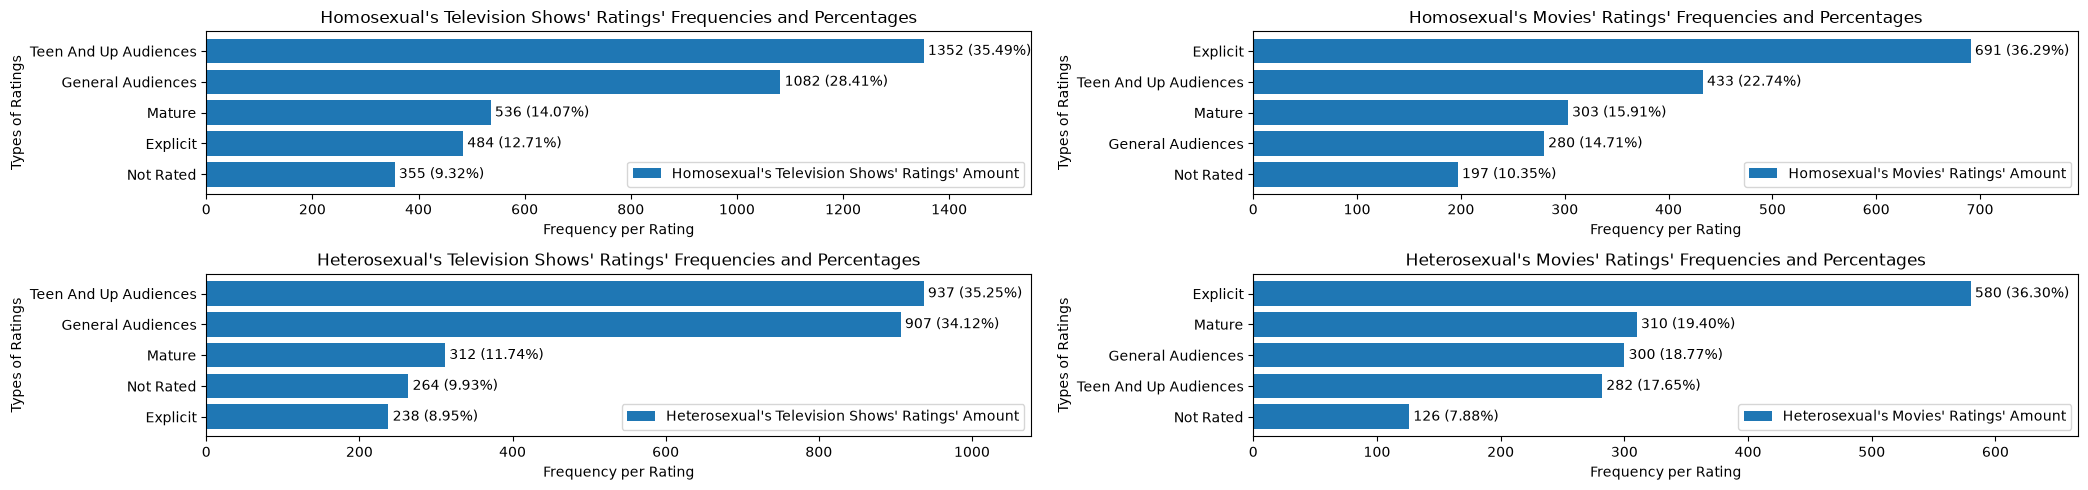

In [18]:
N = len(df_ratings_ff_mm_tv["Rating"]) # Amount of groups
width = 0.8 # Width of the bars
ind = np.arange(N) # Position of the bars on x-axis

fig, ax = plt.subplots(2, 2, figsize=(21, 5)) # Set figure size

# Filtered by F/F + M/M
# Plot a horizontal bar plot
p1 = ax[0, 0].barh(ind, df_ratings_ff_mm_tv["Homosexual Television Show Freq"], width, label="Homosexual's Television Shows' Ratings' Amount")
p2 = ax[0, 1].barh(ind, df_ratings_ff_mm_film["Homosexual Movie Freq"], width, label="Homosexual's Movies' Ratings' Amount")

# Combine the Frequencies and %
ff_mm_labels_tv = [
    f"{freq} ({pct:.2f}%)"
    for freq, pct in zip(
        df_ratings_ff_mm_tv["Homosexual Television Show Freq"],
        df_ratings_ff_mm_tv["Homosexual Television Show %"]
    )
]
ff_mm_labels_film = [
    f"{freq} ({pct:.2f}%)"
    for freq, pct in zip(
        df_ratings_ff_mm_film["Homosexual Movie Freq"],
        df_ratings_ff_mm_film["Homosexual Movie %"]
    )
]

#labels
ax[0, 0].yaxis.set_inverted(True)  # arrange data from top to bottom
ax[0, 0].set_xlabel('Frequency per Rating')
ax[0, 0].set_title('Homosexual\'s Television Shows\' Ratings\' Frequencies and Percentages')
ax[0, 0].set_ylabel('Types of Ratings')
ax[0, 0].set_yticks(ind)
ax[0, 0].set_yticklabels(df_ratings_ff_mm_tv['Rating'])
ax[0, 0].legend(loc='best')

ax[0, 1].yaxis.set_inverted(True)  # arrange data from top to bottom
ax[0, 1].set_xlabel('Frequency per Rating')
ax[0, 1].set_title('Homosexual\'s Movies\' Ratings\' Frequencies and Percentages')
ax[0, 1].set_ylabel('Types of Ratings')
ax[0, 1].set_yticks(ind)
ax[0, 1].set_yticklabels(df_ratings_ff_mm_film['Rating'])
ax[0, 1].legend(loc='best')

ax[0, 0].bar_label(p1, labels=ff_mm_labels_tv, padding=3)
ax[0, 1].bar_label(p2, labels=ff_mm_labels_film, padding=3)

# Add space for the labels
ax[0, 0].set_xlim(right=df_ratings_ff_mm_tv["Homosexual Television Show Freq"].max() * 1.15)
ax[0, 1].set_xlim(right=df_ratings_ff_mm_film["Homosexual Movie Freq"].max() * 1.15)

# Filtered by F/M
# Plot a horizontal bar plot
p1 = ax[1, 0].barh(ind, df_ratings_fm_tv["Heterosexual Television Show Freq"], width, label="Heterosexual's Television Shows' Ratings' Amount")
p2 = ax[1, 1].barh(ind, df_ratings_fm_film["Heterosexual Movie Freq"], width, label="Heterosexual's Movies' Ratings' Amount")

# Combine the Frequencies and %
fm_labels_tv = [
    f"{freq} ({pct:.2f}%)"
    for freq, pct in zip(
        df_ratings_fm_tv["Heterosexual Television Show Freq"],
        df_ratings_fm_tv["Heterosexual Television Show %"]
    )
]
fm_labels_film = [
    f"{freq} ({pct:.2f}%)"
    for freq, pct in zip(
        df_ratings_fm_film["Heterosexual Movie Freq"],
        df_ratings_fm_film["Heterosexual Movie %"]
    )
]

#labels
ax[1, 0].yaxis.set_inverted(True)  # arrange data from top to bottom
ax[1, 0].set_xlabel('Frequency per Rating')
ax[1, 0].set_title('Heterosexual\'s Television Shows\' Ratings\' Frequencies and Percentages')
ax[1, 0].set_ylabel('Types of Ratings')
ax[1, 0].set_yticks(ind)
ax[1, 0].set_yticklabels(df_ratings_fm_tv['Rating'])
ax[1, 0].legend(loc='best')

ax[1, 1].yaxis.set_inverted(True)  # arrange data from top to bottom
ax[1, 1].set_xlabel('Frequency per Rating')
ax[1, 1].set_title('Heterosexual\'s Movies\' Ratings\' Frequencies and Percentages')
ax[1, 1].set_ylabel('Types of Ratings')
ax[1, 1].set_yticks(ind)
ax[1, 1].set_yticklabels(df_ratings_fm_film['Rating'])
ax[1, 1].legend(loc='best')

ax[1, 0].bar_label(p1, labels=fm_labels_tv, padding=3)
ax[1, 1].bar_label(p2, labels=fm_labels_film, padding=3)

# Add space for the labels
ax[1, 0].set_xlim(right=df_ratings_fm_tv["Heterosexual Television Show Freq"].max() * 1.15)
ax[1, 1].set_xlim(right=df_ratings_fm_film["Heterosexual Movie Freq"].max() * 1.15)

plt.tight_layout()
plt.show()

## 2. Archive Warnings

### 2.1 Creating the Archive Warnings Datasets

In [9]:
df_archive_warnings_ff_mm_tv = df_metadata.filter(
    ((pl.col("Category") == "F/F") |
    (pl.col("Category") == "M/M")) &
    ((pl.col("Fandom") == fandoms[0]) |
    (pl.col("Fandom") == fandoms[1]))
).select(pl.col("Archive Warning").value_counts(sort=True)).unnest("Archive Warning").drop_nulls().rename({"count": "Homosexual Television Show Freq"}).with_columns((pl.col("Homosexual Television Show Freq") / ff_mm_tv_amt.item(0,0) * 100).alias("Homosexual Television Show %")) # Filtered by F/F + M/M based on television shows
df_archive_warnings_ff_mm_film = df_metadata.filter(
    ((pl.col("Category") == "F/F") |
    (pl.col("Category") == "M/M")) &
    (pl.col("Fandom") == fandoms[2])
).select(pl.col("Archive Warning").value_counts(sort=True)).unnest("Archive Warning").drop_nulls().rename({"count": "Homosexual Movie Freq"}).with_columns((pl.col("Homosexual Movie Freq") / ff_mm_film_amt.item(0,0) * 100).alias("Homosexual Movie %")) # Filtered by F/F + M/M based on movies

df_archive_warnings_fm_tv = df_metadata.filter(
    (pl.col("Category") == "F/M") &
    ((pl.col("Fandom") == fandoms[0]) |
    (pl.col("Fandom") == fandoms[1]))
).select(pl.col("Archive Warning").value_counts(sort=True)).unnest("Archive Warning").drop_nulls().rename({"count": "Heterosexual Television Show Freq"}).with_columns((pl.col("Heterosexual Television Show Freq") / fm_tv_amt.item(0,0) * 100).alias("Heterosexual Television Show %")) # Filtered by F/M based on television shows
df_archive_warnings_fm_film = df_metadata.filter(
    (pl.col("Category") == "F/M") &
    (pl.col("Fandom") == fandoms[2])
).select(pl.col("Archive Warning").value_counts(sort=True)).unnest("Archive Warning").drop_nulls().rename({"count": "Heterosexual Movie Freq"}).with_columns((pl.col("Heterosexual Movie Freq") / fm_film_amt.item(0,0) * 100).alias("Heterosexual Movie %")) # Filtered by F/M based on movies

print("Homosexual Television Show Archive Warnings Amount:")
df_archive_warnings_ff_mm_tv.show(6)
print("Homosexual Movie Archive Warnings Amount:")
df_archive_warnings_ff_mm_film.show(6)
print("Heterosexual Television Show Archive Warnings Amount:")
df_archive_warnings_fm_tv.show(6)
print("Heterosexual Movie Archive Warnings Amount:")
df_archive_warnings_fm_film.show(6)

Homosexual Television Show Archive Warnings Amount:


Archive Warning,Homosexual Television Show Freq,Homosexual Television Show %
str,u32,f64
"""No Archive Warnings Apply""",2412,63.323707
"""Creator Chose Not To Use Archi…",1068,28.038855
"""Graphic Depictions Of Violence""",104,2.730375
"""Major Character Death""",67,1.758992
"""Rape/Non-Con""",24,0.630087
"""Underage Sex""",22,0.577579


Homosexual Movie Archive Warnings Amount:


Archive Warning,Homosexual Movie Freq,Homosexual Movie %
str,u32,f64
"""Creator Chose Not To Use Archi…",654,34.348739
"""No Archive Warnings Apply""",641,33.665966
"""Underage Sex""",246,12.920168
"""Graphic Depictions Of Violence""",64,3.361345
"""Rape/Non-Con""",24,1.260504
"""Major Character Death""",21,1.102941


Heterosexual Television Show Archive Warnings Amount:


Archive Warning,Heterosexual Television Show Freq,Heterosexual Television Show %
str,u32,f64
"""No Archive Warnings Apply""",1662,62.528217
"""Creator Chose Not To Use Archi…",714,26.862302
"""Major Character Death""",65,2.445448
"""Graphic Depictions Of Violence""",55,2.069225
"""Underage Sex""",22,0.82769
"""Rape/Non-Con""",13,0.48909


Heterosexual Movie Archive Warnings Amount:


Archive Warning,Heterosexual Movie Freq,Heterosexual Movie %
str,u32,f64
"""No Archive Warnings Apply""",683,42.740926
"""Creator Chose Not To Use Archi…",483,30.225282
"""Underage Sex""",102,6.382979
"""Graphic Depictions Of Violence""",95,5.944931
"""Rape/Non-Con""",40,2.503129
"""Major Character Death""",36,2.252816


### 2.2 Visualizing the Archive Warnings Datasets

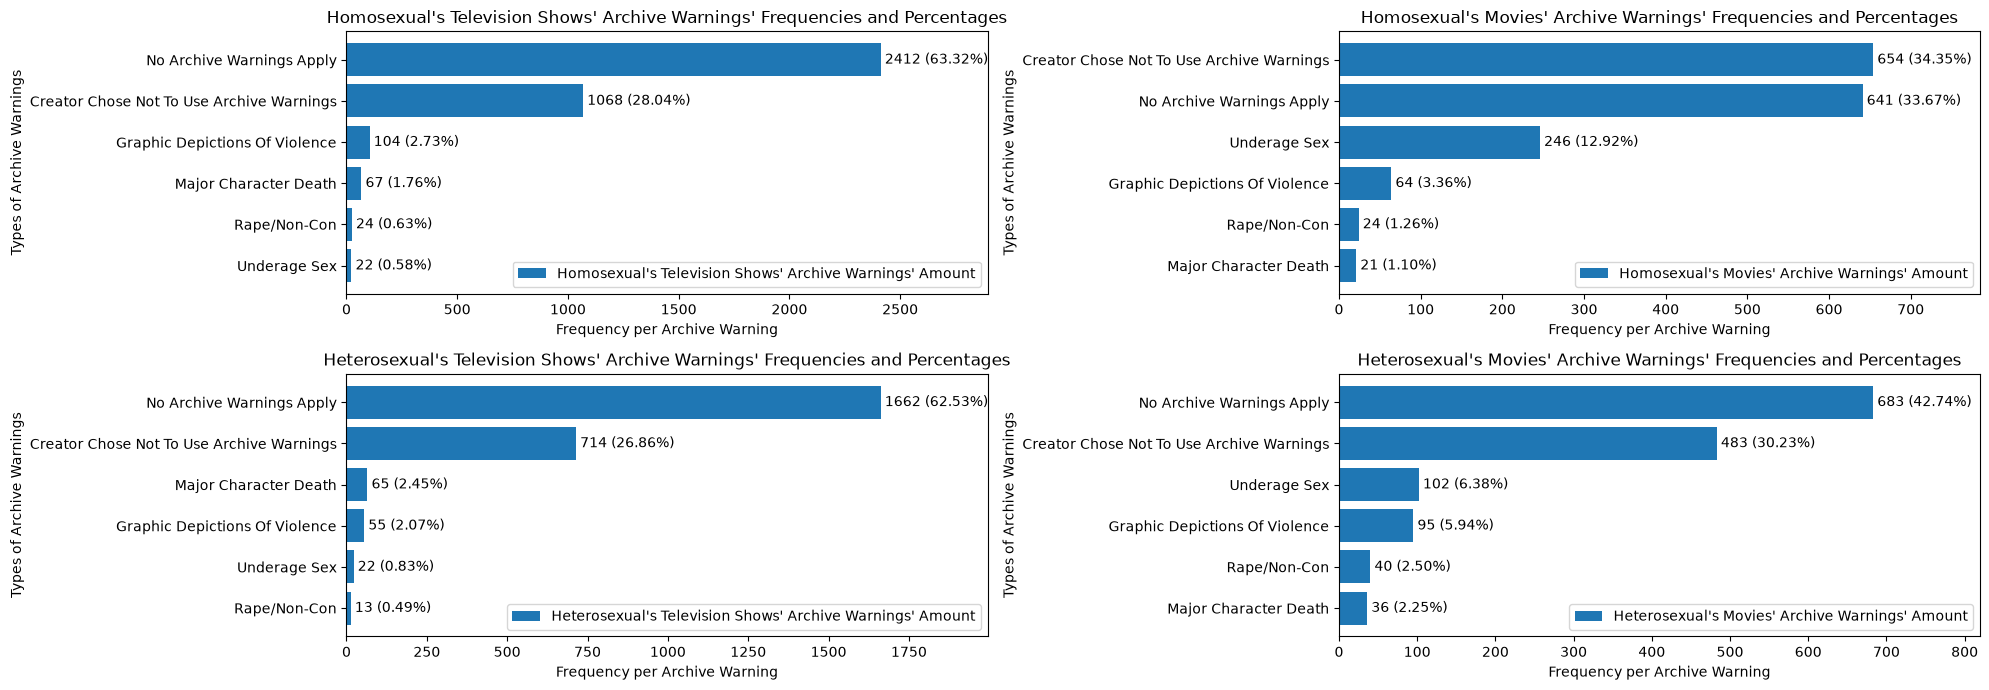

In [10]:
N = len(df_archive_warnings_ff_mm_tv["Archive Warning"]) # Amount of groups
width = 0.8 # Width of the bars
ind = np.arange(N) # Position of the bars on x-axis

fig, ax = plt.subplots(2, 2, figsize=(20, 7)) # Set figure size

# Filtered by F/F + M/M
# Plot a horizontal bar plot
p1 = ax[0, 0].barh(ind, df_archive_warnings_ff_mm_tv["Homosexual Television Show Freq"], width, label="Homosexual's Television Shows' Archive Warnings' Amount")
p2 = ax[0, 1].barh(ind, df_archive_warnings_ff_mm_film["Homosexual Movie Freq"], width, label="Homosexual's Movies' Archive Warnings' Amount")

# Combine the Frequencies and %
ff_mm_labels_tv = [
    f"{freq} ({pct:.2f}%)"
    for freq, pct in zip(
        df_archive_warnings_ff_mm_tv["Homosexual Television Show Freq"],
        df_archive_warnings_ff_mm_tv["Homosexual Television Show %"]
    )
]
ff_mm_labels_film = [
    f"{freq} ({pct:.2f}%)"
    for freq, pct in zip(
        df_archive_warnings_ff_mm_film["Homosexual Movie Freq"],
        df_archive_warnings_ff_mm_film["Homosexual Movie %"]
    )
]

#labels
ax[0, 0].yaxis.set_inverted(True)  # arrange data from top to bottom
ax[0, 0].set_xlabel('Frequency per Archive Warning')
ax[0, 0].set_title('Homosexual\'s Television Shows\' Archive Warnings\' Frequencies and Percentages')
ax[0, 0].set_ylabel('Types of Archive Warnings')
ax[0, 0].set_yticks(ind)
ax[0, 0].set_yticklabels(df_archive_warnings_ff_mm_tv['Archive Warning'])
ax[0, 0].legend(loc='best')

ax[0, 1].yaxis.set_inverted(True)  # arrange data from top to bottom
ax[0, 1].set_xlabel('Frequency per Archive Warning')
ax[0, 1].set_title('Homosexual\'s Movies\' Archive Warnings\' Frequencies and Percentages')
ax[0, 1].set_ylabel('Types of Archive Warnings')
ax[0, 1].set_yticks(ind)
ax[0, 1].set_yticklabels(df_archive_warnings_ff_mm_film['Archive Warning'])
ax[0, 1].legend(loc='best')

ax[0, 0].bar_label(p1, labels=ff_mm_labels_tv, padding=3)
ax[0, 1].bar_label(p2, labels=ff_mm_labels_film, padding=3)

# Add space for the labels
ax[0, 0].set_xlim(right=df_archive_warnings_ff_mm_tv["Homosexual Television Show Freq"].max() * 1.20)
ax[0, 1].set_xlim(right=df_archive_warnings_ff_mm_film["Homosexual Movie Freq"].max() * 1.20)

# Filtered by F/M
# Plot a horizontal bar plot
p1 = ax[1, 0].barh(ind, df_archive_warnings_fm_tv["Heterosexual Television Show Freq"], width, label="Heterosexual's Television Shows' Archive Warnings' Amount")
p2 = ax[1, 1].barh(ind, df_archive_warnings_fm_film["Heterosexual Movie Freq"], width, label="Heterosexual's Movies' Archive Warnings' Amount")

# Combine the Frequencies and %
fm_labels_tv = [
    f"{freq} ({pct:.2f}%)"
    for freq, pct in zip(
        df_archive_warnings_fm_tv["Heterosexual Television Show Freq"],
        df_archive_warnings_fm_tv["Heterosexual Television Show %"]
    )
]
fm_labels_film = [
    f"{freq} ({pct:.2f}%)"
    for freq, pct in zip(
        df_archive_warnings_fm_film["Heterosexual Movie Freq"],
        df_archive_warnings_fm_film["Heterosexual Movie %"]
    )
]

#labels
ax[1, 0].yaxis.set_inverted(True)  # arrange data from top to bottom
ax[1, 0].set_xlabel('Frequency per Archive Warning')
ax[1, 0].set_title('Heterosexual\'s Television Shows\' Archive Warnings\' Frequencies and Percentages')
ax[1, 0].set_ylabel('Types of Archive Warnings')
ax[1, 0].set_yticks(ind)
ax[1, 0].set_yticklabels(df_archive_warnings_fm_tv['Archive Warning'])
ax[1, 0].legend(loc='best')

ax[1, 1].yaxis.set_inverted(True)  # arrange data from top to bottom
ax[1, 1].set_xlabel('Frequency per Archive Warning')
ax[1, 1].set_title('Heterosexual\'s Movies\' Archive Warnings\' Frequencies and Percentages')
ax[1, 1].set_ylabel('Types of Archive Warnings')
ax[1, 1].set_yticks(ind)
ax[1, 1].set_yticklabels(df_archive_warnings_fm_film['Archive Warning'])
ax[1, 1].legend(loc='best')

ax[1, 0].bar_label(p1, labels=fm_labels_tv, padding=3)
ax[1, 1].bar_label(p2, labels=fm_labels_film, padding=3)

# Add space for the labels
ax[1, 0].set_xlim(right=df_archive_warnings_fm_tv["Heterosexual Television Show Freq"].max() * 1.20)
ax[1, 1].set_xlim(right=df_archive_warnings_fm_film["Heterosexual Movie Freq"].max() * 1.20)

plt.tight_layout()
plt.show()

## 3. Additional Tags

### 3.1 Creating the Additional Tags Datasets

In [11]:
# Read the CSV file
df_annotated_tags_fandom_category = pl.read_csv("./data/df_annotated_tags_fandom_category.csv")
df_add_tag_annotation = pl.read_csv("./data/df_additional_tag_annotations.csv")
df_annotated_tags_fandom_category.show()
df_add_tag_annotation.show()

Fandom,Category,Additional Tags,Freq,Character,Narrative,Porn,Kink
str,str,str,i64,str,str,str,str
"""Avatar: The Last Airbender (Ca…","""F/M""","""!!TW!!""",1,"""No Character""","""No Narrative""","""Not Porn""","""Not Kink"""
"""Avatar: The Last Airbender (Ca…","""F/M""","""""Has she always been good at t…",1,"""No Character""","""No Narrative""","""Not Porn""","""Not Kink"""
"""Avatar: The Last Airbender (Ca…","""F/M""","""""I love the smell of incest 😍😍…",1,"""No Character""","""No Narrative""","""Is Porn""","""Not Kink"""
"""Spider-Man: Spider-Verse (Sony…","""F/M""","""""I loved her to the point of i…",1,"""No Character""","""No Narrative""","""Not Porn""","""Not Kink"""
"""DC's Legends of Tomorrow (TV)""","""F/F""","""""Mayday Mayday!""""",1,"""No Character""","""Event-related/Action""","""Not Porn""","""Not Kink"""


Additional Tags,Character,Narrative,Porn,Kink
str,str,str,str,str
"""Fluff""","""No Character""","""Theme/Genre""","""Not Porn""","""Not Kink"""
"""Angst""","""No Character""","""Theme/Genre""","""Not Porn""","""Not Kink"""
"""AvaLance""","""No Character""","""Plot""","""Not Porn""","""Not Kink"""
"""Hurt/Comfort""","""Emotion/Mental State""","""No Narrative""","""Not Porn""","""Not Kink"""
"""Angst with a Happy Ending""","""No Character""","""Theme/Genre""","""Not Porn""","""Not Kink"""


In [12]:
def label_freq(df):
    """
    Calculates the frequency of the annotations.

    Parameter:
        df (DataFrame): Filtered DataFrame.
    Returns:
        df_label_freq (DataFrame): Contains the frequency of the annotations.
    """
    # Add the frequency of the annotations based on unique additional tags
    categories = ["Character", "Narrative", "Porn", "Kink"]

    df_unique_values = pl.DataFrame()
    df_unique_values = pl.concat([df_unique_values, df.select(pl.col(categories[0]).value_counts()).unnest(categories[0]).rename({"Character": "Label"})])
    df_unique_values = pl.concat([df_unique_values, df.select(pl.col(categories[1]).value_counts()).unnest(categories[1]).rename({"Narrative": "Label"})])
    df_unique_values = pl.concat([df_unique_values, df.select(pl.col(categories[2]).value_counts()).unnest(categories[2]).rename({"Porn": "Label"})])
    df_unique_values = pl.concat([df_unique_values, df.select(pl.col(categories[3]).value_counts()).unnest(categories[3]).rename({"Kink": "Label"})])
    df_unique_values = df_unique_values.rename({"count": "Unique Additional Tags Frequency"})

    # Turn into lists
    char_list = ['No Character', 'Biography', 'Physical Feature', 'Emotion/Mental State', 'Relationship', "Personality"]
    nar_list = ['No Narrative', 'Plot', 'Event-related/Action', 'Theme/Genre', 'WorldSetting', 'Narrative Methods', 'Format']
    porn_list = ['Not Porn', 'Is Porn']
    kink_list = ['Not Kink', 'Is Kink']

    # Append the frequency of the annotations based on total additional tags
    df_freq_count = pl.DataFrame()
    for char_label in char_list:
        df_temp_char = pl.DataFrame({
            "Label": char_label,
            "Freq": df.filter(pl.col("Character") == char_label).select(pl.sum("Freq"))
        })
        df_freq_count = pl.concat([df_freq_count, df_temp_char])
    for nar_label in nar_list:
        df_temp_nar = pl.DataFrame({
            "Label": nar_label,
            "Freq": df.filter(pl.col("Narrative") == nar_label).select(pl.sum("Freq"))
        })
        df_freq_count = pl.concat([df_freq_count, df_temp_nar])
    for porn_label in porn_list:
        df_temp_porn = pl.DataFrame({
            "Label": porn_label,
            "Freq": df.filter(pl.col("Porn") == porn_label).select(pl.sum("Freq"))
        })
        df_freq_count = pl.concat([df_freq_count, df_temp_porn])
    for kink_label in kink_list:
        df_temp_kink = pl.DataFrame({
            "Label": kink_label,
            "Freq": df.filter(pl.col("Kink") == kink_label).select(pl.sum("Freq"))
        })
        df_freq_count = pl.concat([df_freq_count, df_temp_kink])
    
    df_freq_count = df_freq_count.rename({"Freq": "Total Additional Tags Frequency"})

    labels = df_freq_count.to_series(0)
    df_label_freq = pl.concat([df_unique_values, df_freq_count], how='align')
    df_label_freq = df_label_freq.sort(pl.col("Total Additional Tags Frequency"), descending=True)
    
    return df_label_freq

In [15]:
character_labels = ["No Character", "Biography", "Physical Feature", "Emotion/Mental State", "Relationship", "Personality"]
narrative_labels = ["No Narrative", "Plot", "Event-related/Action", "Theme/Genre", "WorldSetting", "Narrative Methods", "Format"]
porn_labels = ["Not Porn", "Is Porn"]
kink_labels = ["Not Kink", "Is Kink"]

In [16]:
# Filtered by F/F + M/M based on television shows
df_add_tags_ff_mm_tv = df_annotated_tags_fandom_category.filter(
    ((pl.col("Category") == "F/F") |
    (pl.col("Category") == "M/M")) &
    ((pl.col("Fandom") == fandoms[0]) |
    (pl.col("Fandom") == fandoms[1]))
).group_by("Additional Tags").agg(pl.col("Freq").sum())
df_add_tags_ff_mm_tv = df_add_tags_ff_mm_tv.join(df_add_tag_annotation, on="Additional Tags") # Add annotations
df_add_tags_ff_mm_tv = label_freq(df_add_tags_ff_mm_tv) # Calculate annotation frequencies
df_add_tags_ff_mm_tv = df_add_tags_ff_mm_tv.with_columns(pl.when(pl.col("Label").is_in(character_labels)).then(pl.lit("Character")).when(pl.col("Label").is_in(narrative_labels)).then(pl.lit("Narrative")).when(pl.col("Label").is_in(porn_labels)).then(pl.lit("Porn")).when(pl.col("Label").is_in(kink_labels)).then(pl.lit("Kink")).alias("Category")) # Assign annotation category
df_add_tags_ff_mm_tv = df_add_tags_ff_mm_tv.with_columns((pl.col("Unique Additional Tags Frequency") / pl.col("Unique Additional Tags Frequency").sum().over("Category") * 100).alias("Unique Additional Tags in %"), (pl.col("Total Additional Tags Frequency") / pl.col("Total Additional Tags Frequency").sum().over("Category") * 100).alias("Total Additional Tags in %")) # Calculate percentages within each annotation category

# Filtered by F/F + M/M based on movies
df_add_tags_ff_mm_film = df_annotated_tags_fandom_category.filter(
    ((pl.col("Category") == "F/F") |
    (pl.col("Category") == "M/M")) &
    (pl.col("Fandom") == fandoms[2])
).group_by("Additional Tags").agg(pl.col("Freq").sum())
df_add_tags_ff_mm_film = df_add_tags_ff_mm_film.join(df_add_tag_annotation, on="Additional Tags") # Add annotations
df_add_tags_ff_mm_film = label_freq(df_add_tags_ff_mm_film) # Calculate annotation frequencies
df_add_tags_ff_mm_film = df_add_tags_ff_mm_film.with_columns(pl.when(pl.col("Label").is_in(character_labels)).then(pl.lit("Character")).when(pl.col("Label").is_in(narrative_labels)).then(pl.lit("Narrative")).when(pl.col("Label").is_in(porn_labels)).then(pl.lit("Porn")).when(pl.col("Label").is_in(kink_labels)).then(pl.lit("Kink")).alias("Category")) # Assign annotation category
df_add_tags_ff_mm_film = df_add_tags_ff_mm_film.with_columns((pl.col("Unique Additional Tags Frequency") / pl.col("Unique Additional Tags Frequency").sum().over("Category") * 100).alias("Unique Additional Tags in %"), (pl.col("Total Additional Tags Frequency") / pl.col("Total Additional Tags Frequency").sum().over("Category") * 100).alias("Total Additional Tags in %")) # Calculate percentages within each annotation category

# Filtered by F/M based on television shows
df_add_tags_fm_tv = df_annotated_tags_fandom_category.filter(
    (pl.col("Category") == "F/M")&
    ((pl.col("Fandom") == fandoms[0]) |
    (pl.col("Fandom") == fandoms[1]))
).group_by("Additional Tags").agg(pl.col("Freq").sum())
df_add_tags_fm_tv = df_add_tags_fm_tv.join(df_add_tag_annotation, on="Additional Tags") # Add annotations
df_add_tags_fm_tv = label_freq(df_add_tags_fm_tv) # Calculate annotation frequencies
df_add_tags_fm_tv = df_add_tags_fm_tv.with_columns(pl.when(pl.col("Label").is_in(character_labels)).then(pl.lit("Character")).when(pl.col("Label").is_in(narrative_labels)).then(pl.lit("Narrative")).when(pl.col("Label").is_in(porn_labels)).then(pl.lit("Porn")).when(pl.col("Label").is_in(kink_labels)).then(pl.lit("Kink")).alias("Category")) # Assign annotation category
df_add_tags_fm_tv = df_add_tags_fm_tv.with_columns((pl.col("Unique Additional Tags Frequency") / pl.col("Unique Additional Tags Frequency").sum().over("Category") * 100).alias("Unique Additional Tags in %"), (pl.col("Total Additional Tags Frequency") / pl.col("Total Additional Tags Frequency").sum().over("Category") * 100).alias("Total Additional Tags in %")) # Calculate percentages within each annotation category

# Filtered by F/M based on movies
df_add_tags_fm_film = df_annotated_tags_fandom_category.filter(
    (pl.col("Category") == "F/M") &
    (pl.col("Fandom") == fandoms[2])
).group_by("Additional Tags").agg(pl.col("Freq").sum())
df_add_tags_fm_film = df_add_tags_fm_film.join(df_add_tag_annotation, on="Additional Tags") # Add annotations
df_add_tags_fm_film = label_freq(df_add_tags_fm_film) # Calculate annotation frequencies
df_add_tags_fm_film = df_add_tags_fm_film.with_columns(pl.when(pl.col("Label").is_in(character_labels)).then(pl.lit("Character")).when(pl.col("Label").is_in(narrative_labels)).then(pl.lit("Narrative")).when(pl.col("Label").is_in(porn_labels)).then(pl.lit("Porn")).when(pl.col("Label").is_in(kink_labels)).then(pl.lit("Kink")).alias("Category")) # Assign annotation category
df_add_tags_fm_film = df_add_tags_fm_film.with_columns((pl.col("Unique Additional Tags Frequency") / pl.col("Unique Additional Tags Frequency").sum().over("Category") * 100).alias("Unique Additional Tags in %"), (pl.col("Total Additional Tags Frequency") / pl.col("Total Additional Tags Frequency").sum().over("Category") * 100).alias("Total Additional Tags in %")) # Calculate percentages within each annotation category

print("Homosexual Television Shows' Additional Tag Annotations' Amount:")
df_add_tags_ff_mm_tv.show(17)
print("Homosexual Movies' Additional Tag Annotations' Amount:")
df_add_tags_ff_mm_film.show(17)
print("Heterosexual Television Shows' Additional Tag Annotations' Amount:")
df_add_tags_fm_tv.show(17)
print("Heterosexual Movies' Additional Tag Annotations' Amount:")
df_add_tags_fm_film.show(17)

df_add_tags_ff_mm_tv = df_add_tags_ff_mm_tv.filter(
    (pl.col("Label") != "Not Kink") &
    (pl.col("Label") != "Not Porn")
)
df_add_tags_ff_mm_film = df_add_tags_ff_mm_film.filter(
    (pl.col("Label") != "Not Kink") &
    (pl.col("Label") != "Not Porn")
)
df_add_tags_fm_tv = df_add_tags_fm_tv.filter(
    (pl.col("Label") != "Not Kink") &
    (pl.col("Label") != "Not Porn")
)
df_add_tags_fm_film = df_add_tags_fm_film.filter(
    (pl.col("Label") != "Not Kink") &
    (pl.col("Label") != "Not Porn")
)

print("Homosexual Television Shows' Additional Tag Annotations' Amount:")
df_add_tags_ff_mm_tv.show(17)
print("Homosexual Movies' Additional Tag Annotations' Amount:")
df_add_tags_ff_mm_film.show(17)
print("Heterosexual Television Shows' Additional Tag Annotations' Amount:")
df_add_tags_fm_tv.show(17)
print("Heterosexual Movies' Additional Tag Annotations' Amount:")
df_add_tags_fm_film.show(17)

Homosexual Television Shows' Additional Tag Annotations' Amount:


Label,Unique Additional Tags Frequency,Total Additional Tags Frequency,Category,Unique Additional Tags in %,Total Additional Tags in %
str,u32,i64,str,f64,f64
"""Not Kink""",10324,24189,"""Kink""",98.052996,97.410599
"""Not Porn""",9846,22753,"""Porn""",93.513154,91.627738
"""No Character""",6456,13261,"""Character""",61.316364,53.402867
"""No Narrative""",5640,9894,"""Narrative""",53.566341,39.84375
"""Event-related/Action""",1837,4833,"""Narrative""",17.447051,19.46279
"""Relationship""",1341,4205,"""Character""",12.736252,16.933795
"""Biography""",1474,3780,"""Character""",13.99943,15.222294
"""Theme/Genre""",773,3629,"""Narrative""",7.341628,14.614207
"""Emotion/Mental State""",964,2897,"""Character""",9.155665,11.666398


Homosexual Movies' Additional Tag Annotations' Amount:


Label,Unique Additional Tags Frequency,Total Additional Tags Frequency,Category,Unique Additional Tags in %,Total Additional Tags in %
str,u32,i64,str,f64,f64
"""Not Kink""",7246,20752,"""Kink""",95.97351,92.556086
"""Not Porn""",6731,18278,"""Porn""",89.152318,81.521788
"""No Character""",4481,11331,"""Character""",59.350993,50.537443
"""No Narrative""",4324,10017,"""Narrative""",57.271523,44.676865
"""Event-related/Action""",1629,6399,"""Narrative""",21.576159,28.540208
"""Is Porn""",819,4143,"""Porn""",10.847682,18.478212
"""Relationship""",1034,3897,"""Character""",13.695364,17.381027
"""Biography""",1027,3295,"""Character""",13.602649,14.696044
"""Emotion/Mental State""",707,2593,"""Character""",9.364238,11.565051


Heterosexual Television Shows' Additional Tag Annotations' Amount:


Label,Unique Additional Tags Frequency,Total Additional Tags Frequency,Category,Unique Additional Tags in %,Total Additional Tags in %
str,u32,i64,str,f64,f64
"""Not Kink""",6306,15591,"""Kink""",98.14786,98.192468
"""Not Porn""",6015,14605,"""Porn""",93.618677,91.982617
"""No Character""",3929,8281,"""Character""",61.151751,52.153924
"""No Narrative""",3197,5852,"""Narrative""",49.758755,36.856027
"""Relationship""",889,2907,"""Character""",13.836576,18.308351
"""Biography""",919,2758,"""Character""",14.303502,17.369946
"""Event-related/Action""",1144,2678,"""Narrative""",17.805447,16.866104
"""Theme/Genre""",543,2603,"""Narrative""",8.451362,16.393752
"""Plot""",603,2001,"""Narrative""",9.385214,12.602343


... (6 outputs left out)

Heterosexual Television Shows' Additional Tag Annotations' Amount:


Label,Unique Additional Tags Frequency,Total Additional Tags Frequency,Category,Unique Additional Tags in %,Total Additional Tags in %
str,u32,i64,str,f64,f64
"""No Character""",3929,8281,"""Character""",61.151751,52.153924
"""No Narrative""",3197,5852,"""Narrative""",49.758755,36.856027
"""Relationship""",889,2907,"""Character""",13.836576,18.308351
"""Biography""",919,2758,"""Character""",14.303502,17.369946
"""Event-related/Action""",1144,2678,"""Narrative""",17.805447,16.866104
"""Theme/Genre""",543,2603,"""Narrative""",8.451362,16.393752
"""Plot""",603,2001,"""Narrative""",9.385214,12.602343
"""WorldSetting""",637,1828,"""Narrative""",9.914397,11.512785
"""Emotion/Mental State""",533,1557,"""Character""",8.29572,9.806021


Heterosexual Movies' Additional Tag Annotations' Amount:


Label,Unique Additional Tags Frequency,Total Additional Tags Frequency,Category,Unique Additional Tags in %,Total Additional Tags in %
str,u32,i64,str,f64,f64
"""No Character""",4148,10798,"""Character""",60.238164,54.648515
"""No Narrative""",3796,8311,"""Narrative""",55.126343,42.061845
"""Event-related/Action""",1505,5774,"""Narrative""",21.85594,29.222127
"""Is Porn""",769,4077,"""Porn""",11.167586,20.633635
"""Relationship""",1002,3212,"""Character""",14.551263,16.255883
"""Emotion/Mental State""",645,2333,"""Character""",9.366831,11.807278
"""Theme/Genre""",476,2333,"""Narrative""",6.912576,11.807278
"""Biography""",863,2223,"""Character""",12.532675,11.250569
"""Plot""",426,1542,"""Narrative""",6.186465,7.804039


### 3.2 Visualizing the Additional Tags Datasets

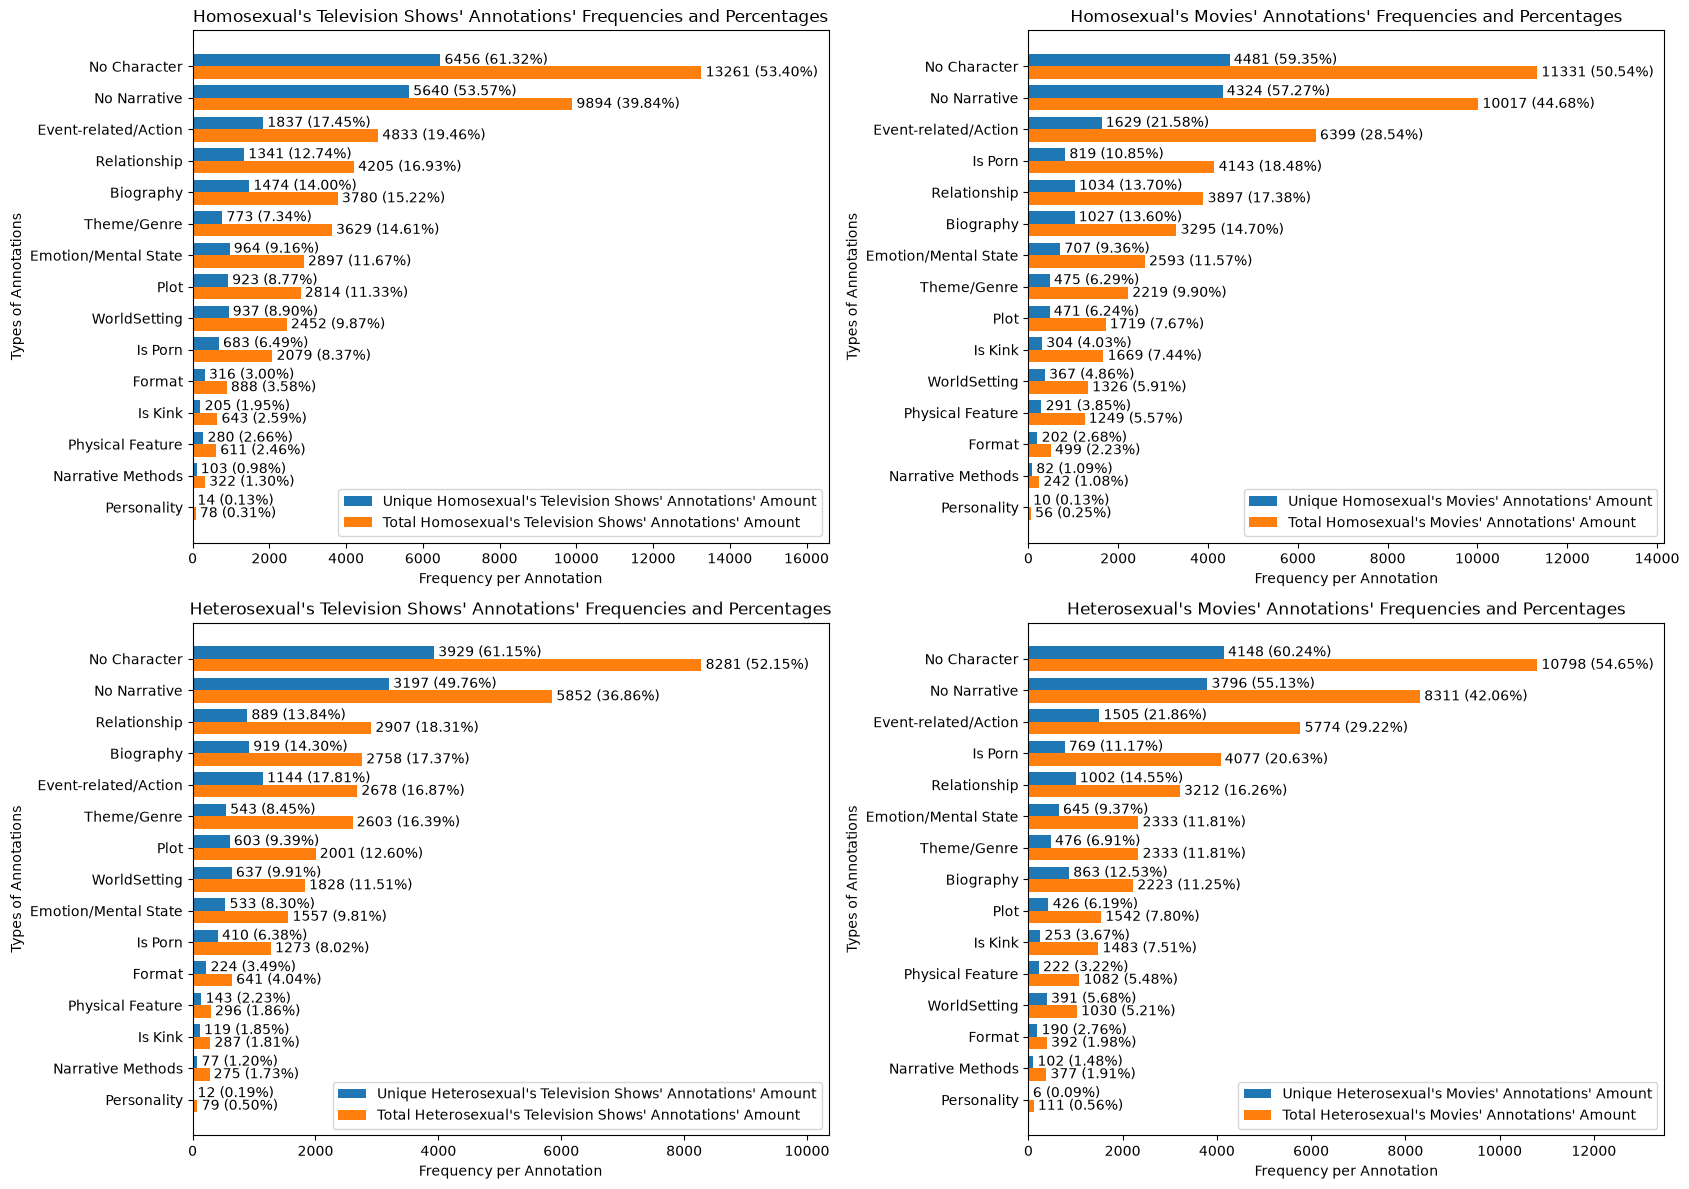

In [17]:
N = len(df_add_tags_ff_mm_tv["Label"]) # Amount of groups
width = 0.4 # Width of the bars
ind = np.arange(N) # Position of the bars on x-axis

fig, ax = plt.subplots(2, 2, figsize=(17, 12)) # Set figure size

# Homosexual Additional Tags based on television shows
# Plot a horizontal bar plot
p1 = ax[0, 0].barh(ind, df_add_tags_ff_mm_tv["Unique Additional Tags Frequency"], width, label="Unique Homosexual's Television Shows' Annotations' Amount")
p2 = ax[0, 0].barh(ind + width, df_add_tags_ff_mm_tv["Total Additional Tags Frequency"], width, label="Total Homosexual's Television Shows' Annotations' Amount")

# Combine the Frequencies and %
ff_mm_labels_unique_tv = [
    f"{freq} ({pct:.2f}%)"
    for freq, pct in zip(
        df_add_tags_ff_mm_tv["Unique Additional Tags Frequency"],
        df_add_tags_ff_mm_tv["Unique Additional Tags in %"]
    )
]

ff_mm_labels_total_tv = [
    f"{freq} ({pct:.2f}%)"
    for freq, pct in zip(
        df_add_tags_ff_mm_tv["Total Additional Tags Frequency"],
        df_add_tags_ff_mm_tv["Total Additional Tags in %"]
    )
]

#labels
ax[0, 0].yaxis.set_inverted(True)  # arrange data from top to bottom
ax[0, 0].set_xlabel('Frequency per Annotation')
ax[0, 0].set_title('Homosexual\'s Television Shows\' Annotations\' Frequencies and Percentages')
ax[0, 0].set_ylabel('Types of Annotations')
ax[0, 0].set_yticks(ind + width * 0.5)
ax[0, 0].set_yticklabels(df_add_tags_ff_mm_tv['Label'])
ax[0, 0].legend(loc='best')

ax[0, 0].bar_label(p1, labels=ff_mm_labels_unique_tv, padding=3)
ax[0, 0].bar_label(p2, labels=ff_mm_labels_total_tv, padding=3)

# Add space for the labels
ax[0, 0].set_xlim(right=df_add_tags_ff_mm_tv["Total Additional Tags Frequency"].max() * 1.25)

# Homosexual Additional Tags based on movies
# Plot a horizontal bar plot
p3 = ax[0, 1].barh(ind, df_add_tags_ff_mm_film["Unique Additional Tags Frequency"], width, label="Unique Homosexual's Movies' Annotations' Amount")
p4 = ax[0, 1].barh(ind + width, df_add_tags_ff_mm_film["Total Additional Tags Frequency"], width, label="Total Homosexual's Movies' Annotations' Amount")

# Combine the Frequencies and %
ff_mm_labels_unique_film = [
    f"{freq} ({pct:.2f}%)"
    for freq, pct in zip(
        df_add_tags_ff_mm_film["Unique Additional Tags Frequency"],
        df_add_tags_ff_mm_film["Unique Additional Tags in %"]
    )
]

ff_mm_labels_total_film = [
    f"{freq} ({pct:.2f}%)"
    for freq, pct in zip(
        df_add_tags_ff_mm_film["Total Additional Tags Frequency"],
        df_add_tags_ff_mm_film["Total Additional Tags in %"]
    )
]

#labels
ax[0, 1].yaxis.set_inverted(True)  # arrange data from top to bottom
ax[0, 1].set_xlabel('Frequency per Annotation')
ax[0, 1].set_title('Homosexual\'s Movies\' Annotations\' Frequencies and Percentages')
ax[0, 1].set_ylabel('Types of Annotations')
ax[0, 1].set_yticks(ind + width * 0.5)
ax[0, 1].set_yticklabels(df_add_tags_ff_mm_film['Label'])
ax[0, 1].legend(loc='best')

ax[0, 1].bar_label(p3, labels=ff_mm_labels_unique_film, padding=3)
ax[0, 1].bar_label(p4, labels=ff_mm_labels_total_film, padding=3)

# Add space for the labels
ax[0, 1].set_xlim(right=df_add_tags_ff_mm_film["Total Additional Tags Frequency"].max() * 1.25)

# Heterosexual Additional Tags based on television shows
# Plot a horizontal bar plot
p1 = ax[1, 0].barh(ind, df_add_tags_fm_tv["Unique Additional Tags Frequency"], width, label="Unique Heterosexual's Television Shows' Annotations' Amount")
p2 = ax[1, 0].barh(ind + width, df_add_tags_fm_tv["Total Additional Tags Frequency"], width, label="Total Heterosexual's Television Shows' Annotations' Amount")

# Combine the Frequencies and %
fm_labels_unique_tv = [
    f"{freq} ({pct:.2f}%)"
    for freq, pct in zip(
        df_add_tags_fm_tv["Unique Additional Tags Frequency"],
        df_add_tags_fm_tv["Unique Additional Tags in %"]
    )
]

fm_labels_total_tv = [
    f"{freq} ({pct:.2f}%)"
    for freq, pct in zip(
        df_add_tags_fm_tv["Total Additional Tags Frequency"],
        df_add_tags_fm_tv["Total Additional Tags in %"]
    )
]

#labels
ax[1, 0].yaxis.set_inverted(True)  # arrange data from top to bottom
ax[1, 0].set_xlabel('Frequency per Annotation')
ax[1, 0].set_title('Heterosexual\'s Television Shows\' Annotations\' Frequencies and Percentages')
ax[1, 0].set_ylabel('Types of Annotations')
ax[1, 0].set_yticks(ind + width * 0.5)
ax[1, 0].set_yticklabels(df_add_tags_fm_tv['Label'])
ax[1, 0].legend(loc='best')

ax[1, 0].bar_label(p1, labels=fm_labels_unique_tv, padding=3)
ax[1, 0].bar_label(p2, labels=fm_labels_total_tv, padding=3)

# Add space for the labels
ax[1, 0].set_xlim(right=df_add_tags_fm_tv["Total Additional Tags Frequency"].max() * 1.25)

# Heterosexual Additional Tags based on movies
# Plot a horizontal bar plot
p3 = ax[1, 1].barh(ind, df_add_tags_fm_film["Unique Additional Tags Frequency"], width, label="Unique Heterosexual's Movies' Annotations' Amount")
p4 = ax[1, 1].barh(ind + width, df_add_tags_fm_film["Total Additional Tags Frequency"], width, label="Total Heterosexual's Movies' Annotations' Amount")

# Combine the Frequencies and %
fm_labels_unique_film = [
    f"{freq} ({pct:.2f}%)"
    for freq, pct in zip(
        df_add_tags_fm_film["Unique Additional Tags Frequency"],
        df_add_tags_fm_film["Unique Additional Tags in %"]
    )
]

fm_labels_total_film = [
    f"{freq} ({pct:.2f}%)"
    for freq, pct in zip(
        df_add_tags_fm_film["Total Additional Tags Frequency"],
        df_add_tags_fm_film["Total Additional Tags in %"]
    )
]

#labels
ax[1, 1].yaxis.set_inverted(True)  # arrange data from top to bottom
ax[1, 1].set_xlabel('Frequency per Annotation')
ax[1, 1].set_title('Heterosexual\'s Movies\' Annotations\' Frequencies and Percentages')
ax[1, 1].set_ylabel('Types of Annotations')
ax[1, 1].set_yticks(ind + width * 0.5)
ax[1, 1].set_yticklabels(df_add_tags_fm_film['Label'])
ax[1, 1].legend(loc='best')

ax[1, 1].bar_label(p3, labels=fm_labels_unique_film, padding=3)
ax[1, 1].bar_label(p4, labels=fm_labels_total_film, padding=3)

# Add space for the labels
ax[1, 1].set_xlim(right=df_add_tags_fm_film["Total Additional Tags Frequency"].max() * 1.25)

plt.tight_layout()
plt.show()